Time Step 1: Hidden State: [[ 0.09901731 -0.02764581  0.12881799]] Output: [[-0.1453478]]
Time Step 2: Hidden State: [[ 0.358989   -0.15806731  0.18666202]] Output: [[0.06731221]]
Time Step 3: Hidden State: [[ 0.60209871 -0.35820564  0.2838229 ]] Output: [[0.34146176]]
Time Step 4: Hidden State: [[ 0.71760694 -0.57704615  0.39115324]] Output: [[0.60297759]]


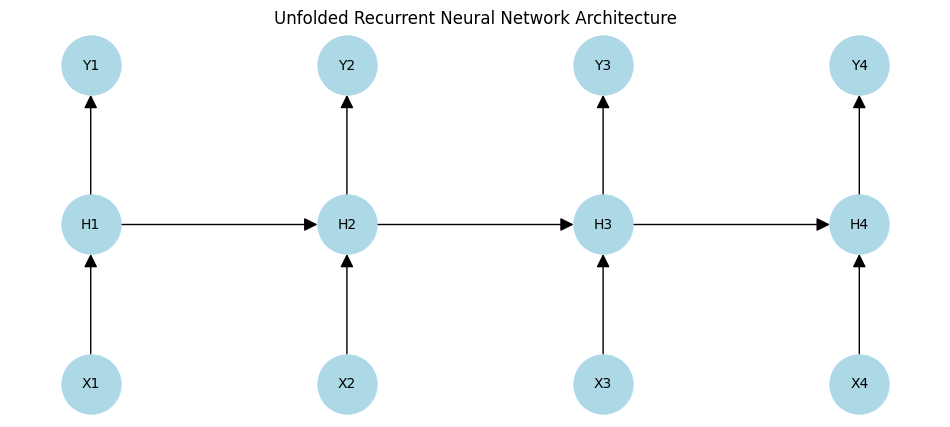


HIDDEN STATES
Time Step 1: [[ 0.09901731 -0.02764581  0.12881799]]
Time Step 2: [[ 0.358989   -0.15806731  0.18666202]]
Time Step 3: [[ 0.60209871 -0.35820564  0.2838229 ]]
Time Step 4: [[ 0.71760694 -0.57704615  0.39115324]]


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import networkx as nx

# 1. Define RNN parameters
time_steps = 4
input_size = 1
hidden_size = 3
output_size = 1

# 2. Initialize weights
np.random.seed(42)

Wx = np.random.randn(
    input_size,
    hidden_size
)

Wh = np.random.randn(
    hidden_size,
    hidden_size
)

Wy = np.random.randn(
    hidden_size,
    output_size
)

bh = np.zeros((1, hidden_size))
by = np.zeros((1, output_size))

# 3. Define input sequence
X = np.array([
    [[0.2], [0.4], [0.6], [0.8]]
])

# 4. RNN forward propagation
h = np.zeros((1, hidden_size))

hidden_states = []
outputs = []

for t in range(time_steps):

    h = np.tanh(
        X[:, t, :] @ Wx
        + h @ Wh
        + bh
    )

    output = h @ Wy + by

    hidden_states.append(h.copy())
    outputs.append(output.copy())

    print(
        f"Time Step {t+1}:",
        "Hidden State:", h,
        "Output:", output
    )

# 5. Build unfolded RNN graph
G = nx.DiGraph()

for t in range(time_steps):

    G.add_node(
        f"X{t+1}",
        layer="input"
    )

    G.add_node(
        f"H{t+1}",
        layer="hidden"
    )

    G.add_node(
        f"Y{t+1}",
        layer="output"
    )

    G.add_edge(
        f"X{t+1}",
        f"H{t+1}"
    )

    G.add_edge(
        f"H{t+1}",
        f"Y{t+1}"
    )

    if t > 0:

        G.add_edge(
            f"H{t}",
            f"H{t+1}"
        )

# 6. Define node positions
pos = {}

for t in range(time_steps):

    pos[f"X{t+1}"] = (t * 2, 0)

    pos[f"H{t+1}"] = (t * 2, 1)

    pos[f"Y{t+1}"] = (t * 2, 2)

# 7. Draw RNN architecture
plt.figure(figsize=(12, 5))

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=1800,
    node_color="lightblue",
    font_size=10,
    arrows=True,
    arrowsize=20
)

plt.title("Unfolded Recurrent Neural Network Architecture")

plt.axis("off")
plt.show()

# 8. Display hidden states
print("\nHIDDEN STATES")

for i, state in enumerate(hidden_states):

    print(
        f"Time Step {i+1}:",
        state
    )